<a href="https://colab.research.google.com/github/charifa708/TP-pr-traitement/blob/main/TP_pr%C3%A9traitement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")

In [2]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [5]:
df = df.drop(columns=["alive", "class", "who", "adult_male", "embark_town", "alone"])
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,deck
0,0,3,male,22.0,1,0,7.2500,S,NaN
1,1,1,female,38.0,1,0,71.2833,C,C
2,1,3,female,26.0,0,0,7.9250,S,NaN
3,1,1,female,35.0,1,0,53.1000,S,C
4,0,3,male,35.0,0,0,8.0500,S,NaN


In [6]:
print(df.isnull().mean() * 100)

survived     0.000000
pclass       0.000000
sex          0.000000
age         19.865320
sibsp        0.000000
parch        0.000000
fare         0.000000
embarked     0.224467
deck        77.216611
dtype: float64


In [7]:
df = df.drop(columns=["deck"])
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

In [9]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0


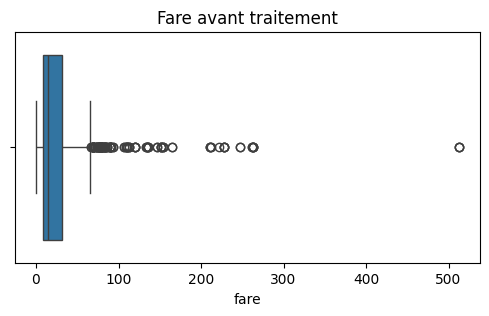

In [10]:
plt.figure(figsize=(6, 3))
sns.boxplot(x=df["fare"])
plt.title("Fare avant traitement")
plt.show()

In [11]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 - Q1

borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

aberrantes = (df["fare"] < borne_basse) | (df["fare"] > borne_haute)
print("Borne haute :", borne_haute)
print("Nombre de valeurs aberrantes :", aberrantes.sum())

Borne haute : 65.6344
Nombre de valeurs aberrantes : 116


In [12]:
df.loc[aberrantes, "fare"] = df["fare"].median()

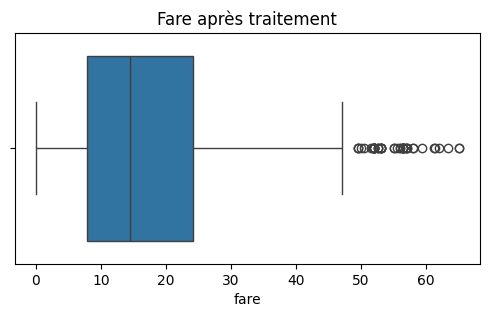

In [13]:
plt.figure(figsize=(6, 3))
sns.boxplot(x=df["fare"])
plt.title("Fare après traitement")
plt.show()

In [14]:
df.select_dtypes(exclude="number").columns.tolist()

['sex', 'embarked']

In [15]:
df = pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True, dtype=int)
df.head()

,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,14.4542,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


In [16]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

colonnes = ["age", "fare"]

# Normalisation : valeurs entre 0 et 1
df_minmax = df.copy()
df_minmax[colonnes] = MinMaxScaler().fit_transform(df[colonnes])

# Standardisation : moyenne 0, écart-type 1
df_zscore = df.copy()
df_zscore[colonnes] = StandardScaler().fit_transform(df[colonnes])

In [17]:
print(df_minmax[colonnes].describe().loc[["min", "max"]])
print(df_zscore[colonnes].describe().loc[["mean", "std"]])

     age  fare
min  0.0   0.0
max  1.0   1.0
               age          fare
mean  2.272780e-16 -9.569599e-17
std   1.000562e+00  1.000562e+00


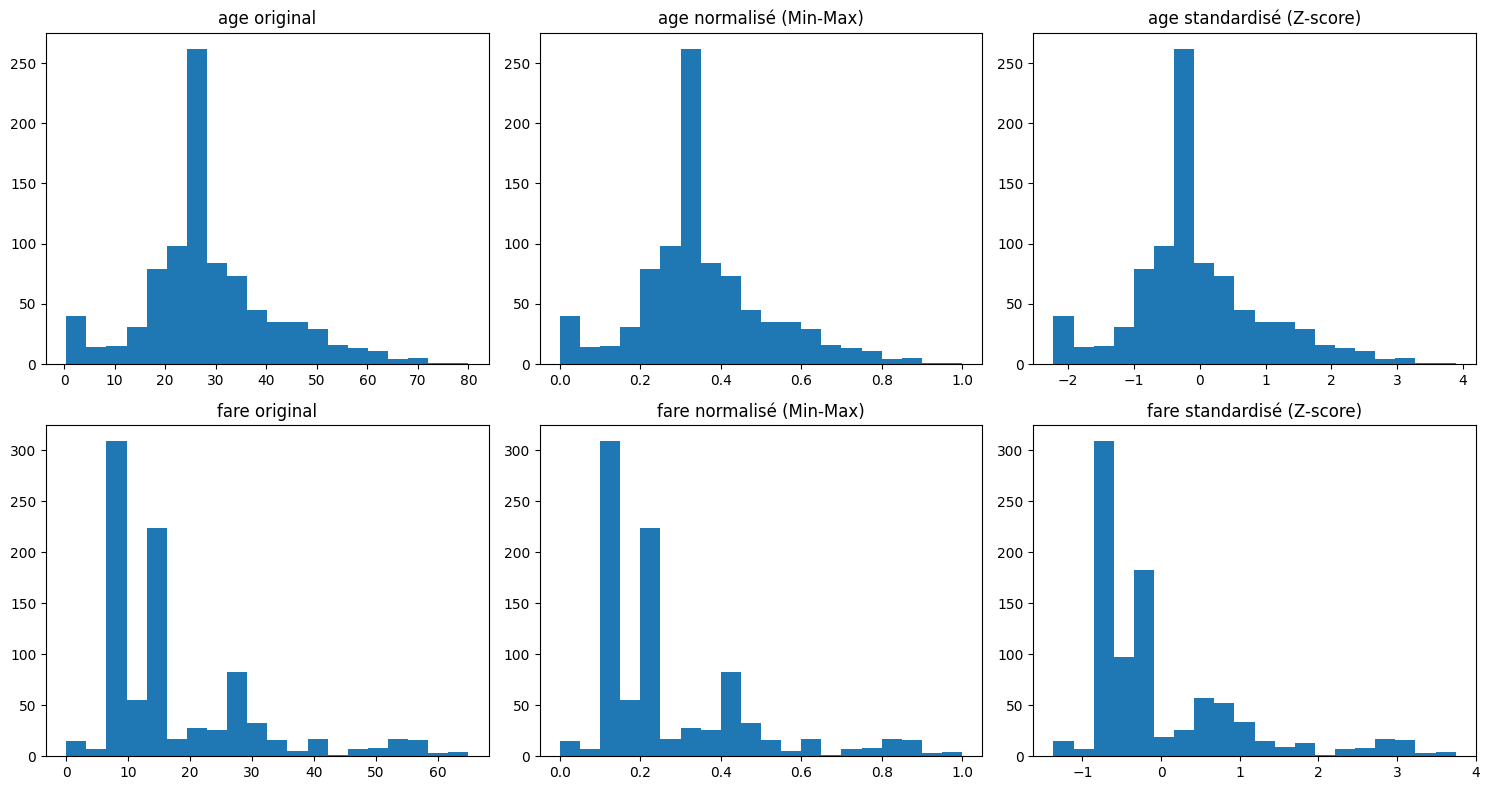

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(colonnes):
    axes[i, 0].hist(df[col], bins=20)
    axes[i, 0].set_title(f"{col} original")

    axes[i, 1].hist(df_minmax[col], bins=20)
    axes[i, 1].set_title(f"{col} normalisé (Min-Max)")

    axes[i, 2].hist(df_zscore[col], bins=20)
    axes[i, 2].set_title(f"{col} standardisé (Z-score)")

plt.tight_layout()
plt.show()

survived
0    549
1    342
Name: count, dtype: int64
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


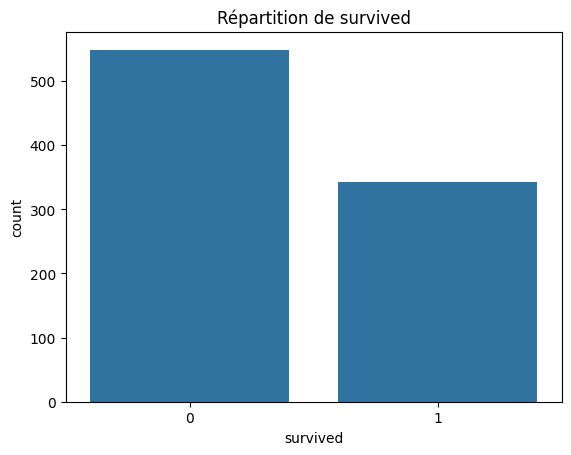

In [19]:
print(df["survived"].value_counts())
print(df["survived"].value_counts(normalize=True) * 100)

sns.countplot(x="survived", data=df)
plt.title("Répartition de survived")
plt.show()

In [20]:
X = df.drop(columns=["survived"])
y = df["survived"]

In [21]:
!pip install imbalanced-learn

In [22]:
from imblearn.under_sampling import RandomUnderSampler

X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X, y)
print(y_under.value_counts())

survived
0    342
1    342
Name: count, dtype: int64


In [23]:
from imblearn.over_sampling import SMOTE

X_smote, y_smote = SMOTE(random_state=42).fit_resample(X, y)
print(y_smote.value_counts())

survived
0    549
1    549
Name: count, dtype: int64
